# Cart-pole closed-loop tasks: simulated prediction for all three behaviours

Follows the handout's standard process: **open-loop move** (stops after about one half-period, about 0.33 s) → **0.7 s hold** with no feedback → **10 s of closed-loop control**.

Feedback law (cart acceleration command, updated every controller tick):

$$\ddot x_{cmd} = K_p\,\theta + K_d\,\dot\theta$$

with $I\ddot\theta + b\dot\theta + mgl\sin\theta = -ml\,\ddot x\cos\theta$, θ measured from the downward vertical.
In this convention **positive K_d adds damping**, **negative K_d removes damping (adds energy)**, positive K_p raises the frequency.

| Task | Goal | What the gains have to do |
|---|---|---|
| 1 Quash | angle below 10 % of the initial amplitude, as fast as possible | strong positive K_d |
| 2 Maintain | keep the initial amplitude | K_d just cancels the natural damping (small, negative) |
| 3 Tune | keep the amplitude **and** oscillate as far above the natural frequency as possible | K_d as in task 2, plus a large positive K_p |

**Workflow:** put the formula person's gains in the next cell → Run All → later drop in the hardware CSVs and Run All again (curves appear automatically).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

## 1. Inputs

In [4]:
# =====================================================================
#  >>>>>>  GAINS: replace with the formula person's values  <<<<<<
#  cart acceleration command   x_ddot = KP * theta + KD * theta_dot
#  KP in (m/s^2) per rad,   KD in (m/s^2) per (rad/s)
# =====================================================================
GAINS = {
    "Quash":    {"KP": 0.0, "KD":  2.0},    # PLACEHOLDER (task 1)
    "Maintain": {"KP": 0.0, "KD": -0.010},  # PLACEHOLDER (task 2)  ~ -b/(m*l) for the assumed damping
    "Tune":     {"KP": 8.0, "KD": -0.010},  # PLACEHOLDER (task 3)
}
# --- OR let the notebook compute the gains from the formula person's derivation (section 3b) ---
USE_FORMULA_GAINS = True      # True -> GAINS above are overwritten by the formula results
QUASH_T_TARGET = 0.5          # task 1: time to reach 10 % [s]  -> zeta*wc = ln(10)/t
QUASH_ZETA = 0.7              # task 1: desired closed-loop damping ratio (free choice; sets wc and so Kp)
TUNE_FREQ_HZ = 2.0            # task 3: desired closed-loop frequency [Hz], must be above the natural frequency
KP_SIGN = +1   # use -1 if the formula person's sign convention for KP is the opposite of the one above
KD_SIGN = +1   # same for KD
# =====================================================================

# Standard process from the handout
MOVE_TIME_S = 0.33          # open-loop move duration (about one half-period)
D_MOVE_MM = None            # None -> distance computed so the move lasts MOVE_TIME_S; or enter the distance you actually use
HOLD_TIME = 0.7             # stationary, feedback off [s]
CONTROL_DURATION = 10.0     # closed-loop time [s]

# Pendulum
m, l, g = 0.0339, 0.12, 9.81
W0_MEASURED = 9.686         # natural frequency [rad/s]   (period 0.649 s, half-period 0.32 s)
ZETA = 0.005                # natural damping ratio. Rough fit only: see section 3 to get it from the hardware control run
USE_MEASURED_DAMPING = False  # True -> overwrite ZETA with the value estimated from the hardware control log

# Cart limits
A_MAX = 2.62103             # [m/s^2]
V_MAX = 0.16343             # [m/s]

# Controller implementation (match the Arduino loop)
DT_CTRL = 0.01              # controller update period [s]
ANGLE_QUANT_DEG = 0.15      # encoder resolution [deg]; None = perfect sensor
RATE_FILTER = 0.0           # 0 = raw backward difference; 0.7 = heavier low-pass on theta_dot

# Hardware logs (CSV text or Excel). Missing files are skipped, so you can add them later.
HW_FILES = {
    "Control":  "hw_control.csv",    # same move, NO feedback afterwards
    "Quash":    "hw_quash.csv",
    "Maintain": "hw_maintain.csv",
    "Tune":     "hw_tune.csv",
}
LOG_TIME_COL = None         # None -> first column.   Handout order: time, cart position, angle
LOG_ANGLE_COL = None        # None -> THIRD column if there are 3+ columns, else the second
LOG_TIME_UNITS = "s"        # "s" or "ms"
LOG_ANGLE_UNITS = "deg"     # "deg" or "rad"
LOG_TIME_ZERO_AT = "start"  # "start": t = 0 is the start of the cart move;  "control": t = 0 is when feedback switches on

## 2. Timing of the standard process and hardware data loading

In [6]:
def move_profile(D):
    d_ramp = V_MAX**2 / A_MAX
    if D >= d_ramp:
        ta, tc = V_MAX / A_MAX, (D - d_ramp) / V_MAX
    else:
        ta, tc = np.sqrt(D / A_MAX), 0.0
    return ta, tc, 2 * ta + tc

def dist_for_time(T):
    if T >= 2 * V_MAX / A_MAX:
        return V_MAX**2 / A_MAX + V_MAX * (T - 2 * V_MAX / A_MAX)
    return A_MAX * (T / 2) ** 2

D_USED_MM = D_MOVE_MM if D_MOVE_MM is not None else 1000 * dist_for_time(MOVE_TIME_S)
_, _, T_MOVE = move_profile(D_USED_MM / 1000)
T_CTRL = T_MOVE + HOLD_TIME          # feedback switches on
T_END = T_CTRL + CONTROL_DURATION
print(f"Move distance {D_USED_MM:.1f} mm, move ends at {T_MOVE:.2f} s, feedback on at {T_CTRL:.2f} s, run ends at {T_END:.2f} s")

def load_log(path):
    try:
        try:
            df = pd.read_csv(path)
        except Exception:
            df = pd.read_excel(path)
    except FileNotFoundError:
        return None
    tcol = LOG_TIME_COL or df.columns[0]
    acol = LOG_ANGLE_COL or (df.columns[2] if df.shape[1] >= 3 else df.columns[1])
    t = df[tcol].to_numpy(float) / (1000.0 if LOG_TIME_UNITS == "ms" else 1.0)
    th = df[acol].to_numpy(float)
    if LOG_ANGLE_UNITS == "rad":
        th = np.degrees(th)
    t = t - t[0]
    if LOG_TIME_ZERO_AT == "control":
        t = t + T_CTRL
    return t, th

hw = {k: load_log(p) for k, p in HW_FILES.items()}
for k, v in hw.items():
    print(f"hardware {k:9s}: " + (f"{len(v[0])} samples, {v[0][0]:.2f} to {v[0][-1]:.2f} s" if v else f"not found ({HW_FILES[k]}), skipped"))

Move distance 43.7 mm, move ends at 0.33 s, feedback on at 1.03 s, run ends at 11.03 s
hardware Control  : not found (hw_control.csv), skipped
hardware Quash    : not found (hw_quash.csv), skipped
hardware Maintain : not found (hw_maintain.csv), skipped
hardware Tune     : not found (hw_tune.csv), skipped


## 3. Natural damping from the hardware control run (optional, but task 2 depends on it)

For task 2 the K_d has to cancel the natural damping: $K_d \approx -b/(ml)$. Fit the decay of the hardware **control** run to get b. The fit assumes viscous damping, so if the peaks fall linearly rather than exponentially the estimate is rough.

In [8]:
from scipy.signal import find_peaks

I_est = m * g * l / W0_MEASURED**2
if hw["Control"] is not None:
    t_c, th_c = hw["Control"]
    mask = t_c >= T_MOVE
    ip, _ = find_peaks(np.abs(th_c[mask]), prominence=0.3)
    pk_t, pk_a = t_c[mask][ip], np.abs(th_c[mask])[ip]
    keep = pk_a > 1.0                       # ignore the noise floor
    if keep.sum() >= 4:
        sigma = -np.polyfit(pk_t[keep], np.log(pk_a[keep]), 1)[0]     # envelope decay rate [1/s]
        zeta_est = sigma / W0_MEASURED
        b_est = 2 * I_est * sigma
        print(f"Hardware control decay: sigma = {sigma:.3f} 1/s  ->  zeta = {zeta_est:.4f},  b = {b_est:.3e} N m s/rad")
        print(f"Task 2 starting point:  KD ~ -b/(m*l) = {-b_est/(m*l):.4f}")
        if USE_MEASURED_DAMPING:
            ZETA = zeta_est
            print("ZETA overwritten with the measured value.")
    else:
        print("Too few clear peaks in the control log to estimate damping.")
else:
    print(f"No hardware control log yet. The simulation uses ZETA = {ZETA} -> KD for task 2 ~ {-2*ZETA*I_est*W0_MEASURED/(m*l):.4f}")

No hardware control log yet. The simulation uses ZETA = 0.005 -> KD for task 2 ~ -0.0101


## 3b. Gains from the formula person's derivation

Closed loop: $\ddot\theta + (a + d\,k_d)\dot\theta + (c + d\,k_p)\theta = 0$ with $a = b/I,\; c = mgl/I,\; d = ml/I$.
Matching $s^2 + 2\zeta\omega_c s + \omega_c^2$ gives

$$k_d = \frac{2\zeta\omega_c - a}{d}, \qquad k_p = \frac{\omega_c^2 - c}{d}$$

- **Quash:** the envelope is $A_0 e^{-\zeta\omega_c t}$, so reaching 10 % at time $t$ needs $\zeta\omega_c = \ln 10 / t$.
- **Maintain:** $\zeta = 0$ and $\omega_c = \omega_n$, so $k_d = -a/d$ and $k_p = 0$.
- **Tune:** $\zeta = 0$ (so $k_d = -a/d$ again) and $\omega_c > \omega_n$.

These use the same b, I and ω₀ as the simulation. If the formulas and the simulation use different values, the prediction and the hardware will disagree.

In [10]:
# Same parameters as the simulation (I is set from the measured natural frequency, b from ZETA)
I_f = m * g * l / W0_MEASURED**2
b_f = 2 * ZETA * I_f * W0_MEASURED
a_, c_, d_ = b_f / I_f, m * g * l / I_f, m * l / I_f
wn = np.sqrt(c_)

def gains_from_formulas(zeta_c, wc):
    return (wc**2 - c_) / d_, (2 * zeta_c * wc - a_) / d_        # kp, kd

if USE_FORMULA_GAINS:
    zw = np.log(10) / QUASH_T_TARGET                              # zeta*wc for task 1
    wc1 = zw / QUASH_ZETA
    kp1, kd1 = gains_from_formulas(QUASH_ZETA, wc1)
    kp2, kd2 = gains_from_formulas(0.0, wn)                       # maintain: zeta = 0, wc = wn
    kp3, kd3 = gains_from_formulas(0.0, 2 * np.pi * TUNE_FREQ_HZ) # tune: zeta = 0, wc > wn
    GAINS = {"Quash": {"KP": kp1, "KD": kd1}, "Maintain": {"KP": kp2, "KD": kd2}, "Tune": {"KP": kp3, "KD": kd3}}
    print(f"a = b/I = {a_:.3f} 1/s,  c = mgl/I = {c_:.2f} 1/s^2 (wn = {wn:.3f} rad/s = {wn/2/np.pi:.3f} Hz),  d = ml/I = {d_:.3f}")
    print(f"Quash   : zeta*wc = {zw:.2f}, zeta = {QUASH_ZETA}, wc = {wc1:.2f} rad/s  ->  Kp = {kp1:.3f}, Kd = {kd1:.3f}")
    print(f"Maintain: zeta = 0, wc = wn                           ->  Kp = {kp2:.3f}, Kd = {kd2:.4f}")
    print(f"Tune    : zeta = 0, wc = {2*np.pi*TUNE_FREQ_HZ:.2f} rad/s ({TUNE_FREQ_HZ} Hz)  ->  Kp = {kp3:.3f}, Kd = {kd3:.4f}")
    # how sensitive the maintain gain is to the damping used
    print("\nTask 2 gain  Kd = -b/(m*l)  scales directly with the damping you assume:")
    for z_ in (0.005, 0.046, 0.5):
        print(f"   zeta = {z_:<6} ->  Kd = {-2*z_*W0_MEASURED*I_f/(m*l):.3f}")
else:
    print("Using the GAINS typed in the inputs cell.")

a = b/I = 0.097 1/s,  c = mgl/I = 93.82 1/s^2 (wn = 9.686 rad/s = 1.542 Hz),  d = ml/I = 9.564
Quash   : zeta*wc = 4.61, zeta = 0.7, wc = 6.58 rad/s  ->  Kp = -5.284, Kd = 0.953
Maintain: zeta = 0, wc = wn                           ->  Kp = 0.000, Kd = -0.0101
Tune    : zeta = 0, wc = 12.57 rad/s (2.0 Hz)  ->  Kp = 6.702, Kd = -0.0101

Task 2 gain  Kd = -b/(m*l)  scales directly with the damping you assume:
   zeta = 0.005  ->  Kd = -0.010
   zeta = 0.046  ->  Kd = -0.093
   zeta = 0.5    ->  Kd = -1.013


## 4. Simulation

In [12]:
I = m * g * l / W0_MEASURED**2
w0 = W0_MEASURED
b = 2 * ZETA * I * w0

def open_loop_accel(t, ta, tc, T):
    if t < ta:        return  A_MAX
    if t < ta + tc:   return  0.0
    if t < T:         return -A_MAX
    return 0.0

def deriv(y, a):
    x, v, th, w = y
    return np.array([v, a, w, (-b * w - m * g * l * np.sin(th) - m * l * a * np.cos(th)) / I])

def simulate(kp, kd, feedback=True, dt=0.0005):
    kp, kd = KP_SIGN * kp, KD_SIGN * kd
    ta, tc, T_move = move_profile(D_USED_MM / 1000)
    n = int(round(T_END / dt))
    y = np.zeros(4)                                   # x, v, theta, omega
    T = np.zeros(n + 1); Y = np.zeros((n + 1, 4)); A = np.zeros(n + 1)
    next_ctrl, a_fb, th_prev, w_filt = 0.0, 0.0, 0.0, 0.0
    q = np.radians(ANGLE_QUANT_DEG) if ANGLE_QUANT_DEG else None
    stopped = False
    for k in range(n):
        t = k * dt
        if t >= next_ctrl:                            # controller tick (runs all the time so theta_dot is valid when feedback starts)
            th_meas = y[2] if q is None else np.round(y[2] / q) * q
            w_raw = (th_meas - th_prev) / DT_CTRL
            w_filt = RATE_FILTER * w_filt + (1 - RATE_FILTER) * w_raw
            a_fb = float(np.clip(kp * th_meas + kd * w_filt, -A_MAX, A_MAX))
            th_prev, next_ctrl = th_meas, next_ctrl + DT_CTRL
        if t < T_move:
            a = open_loop_accel(t, ta, tc, T_move)
        elif t < T_CTRL:                              # hold: cart stationary
            if not stopped:
                y[1], stopped = 0.0, True
            a = 0.0
        else:                                         # closed loop
            a = a_fb if feedback else 0.0
            v_new = y[1] + a * dt
            if abs(v_new) > V_MAX:                    # cart speed limit
                a = (np.sign(v_new) * V_MAX - y[1]) / dt
        k1 = deriv(y, a); k2 = deriv(y + 0.5 * dt * k1, a)
        k3 = deriv(y + 0.5 * dt * k2, a); k4 = deriv(y + dt * k3, a)
        y = y + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        T[k + 1], Y[k + 1], A[k] = t + dt, y, a
    return T, Y, A

def dominant_freq(t, th):
    dt = np.median(np.diff(t)); tt = np.arange(t[0], t[-1], dt)
    x = np.interp(tt, t, th); x = x - x.mean()
    spec = np.abs(np.fft.rfft(x * np.hanning(len(x)), n=8 * len(x)))
    fr = np.fft.rfftfreq(8 * len(x), dt)
    band = (fr > 0.5) & (fr < 4.0)
    return fr[band][np.argmax(spec[band])]

def analyze(t, th):
    # initial amplitude = peak |theta| during the hold, before feedback starts
    hold = (t >= T_MOVE) & (t < T_CTRL)
    ctrl = t >= T_CTRL
    A0 = np.abs(th[hold]).max()
    tc_, xc = t[ctrl], np.abs(th[ctrl])
    above = np.where(xc > 0.1 * A0)[0]
    if len(above) == 0:
        settle = 0.0
    elif above[-1] >= len(xc) - 1:
        settle = np.nan                                # never stays below 10 %
    else:
        settle = tc_[above[-1] + 1] - T_CTRL
    end_ratio = xc[tc_ >= tc_[-1] - 1.5].max() / A0   # amplitude over the last 1.5 s relative to initial
    return dict(A0=A0, settle=settle, end_ratio=end_ratio, freq=dominant_freq(tc_, th[ctrl]))

def run_case(kp, kd, feedback=True):
    t, Y, a = simulate(kp, kd, feedback)
    th = np.degrees(Y[:, 2])
    r = analyze(t, th)
    ctrl = t >= T_CTRL
    r.update(t=t, th=th, travel_mm=1000 * np.ptp(Y[ctrl, 0]), peak_acc=np.abs(a[ctrl]).max())
    return r

print(f"Model: I = {I:.3e} kg m^2, w0 = {w0:.3f} rad/s ({w0/2/np.pi:.3f} Hz), zeta = {ZETA:.4f}, b = {b:.3e}")

Model: I = 4.254e-04 kg m^2, w0 = 9.686 rad/s (1.542 Hz), zeta = 0.0050, b = 4.120e-05


## 5. Run the three tasks and summarise

In [14]:
sim = {name: run_case(g_["KP"], g_["KD"]) for name, g_ in GAINS.items()}
sim_ctrl = run_case(0, 0, feedback=False)
hw_res = {name: (analyze(*hw[name]) if hw[name] is not None else None) for name in GAINS}
A0 = sim_ctrl["A0"]
print(f"Initial amplitude (peak during the hold): {A0:.1f} deg" + ("   <- below the handout's 15 deg minimum, lengthen/strengthen the move" if A0 < 15 else ""))
print(f"Natural frequency: {w0/2/np.pi:.3f} Hz\n")

fmt = lambda v, f: "-" if v is None or (isinstance(v, float) and np.isnan(v)) else format(v, f)
rows = []
for name, g_ in GAINS.items():
    s, h = sim[name], hw_res[name]
    rows.append({"task": name, "Kp": g_["KP"], "Kd": g_["KD"],
                 "settle to <10% sim [s]": fmt(s["settle"], ".2f"), "hw": fmt(h and h["settle"], ".2f"),
                 "amp kept at end sim": fmt(s["end_ratio"], ".2f"), "hw ": fmt(h and h["end_ratio"], ".2f"),
                 "freq sim [Hz]": "-" if name == "Quash" else fmt(s["freq"], ".2f"), "hw  ": "-" if name == "Quash" else fmt(h and h["freq"], ".2f"),
                 "cart travel [mm]": f"{s['travel_mm']:.0f}", "peak accel [m/s^2]": f"{s['peak_acc']:.2f}"})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nCart acceleration limit: {A_MAX:.2f} m/s^2. If 'peak accel' reaches it, the cart is saturating and the prediction depends on the nonlinear limit, not just the formulas.")

Initial amplitude (peak during the hold): 17.3 deg
Natural frequency: 1.542 Hz

    task        Kp        Kd settle to <10% sim [s] hw amp kept at end sim hw  freq sim [Hz] hw   cart travel [mm] peak accel [m/s^2]
   Quash -5.284408  0.952937                   1.34  -                0.00   -             -    -             1248               2.01
Maintain  0.000000 -0.010128                      -  -                0.97   -          1.54    -               11               0.03
    Tune  6.702005 -0.010128                      -  -                1.06   -          1.97    -              191               2.14

Cart acceleration limit: 2.62 m/s^2. If 'peak accel' reaches it, the cart is saturating and the prediction depends on the nonlinear limit, not just the formulas.


## 6. Figure: the three behaviours on one graph

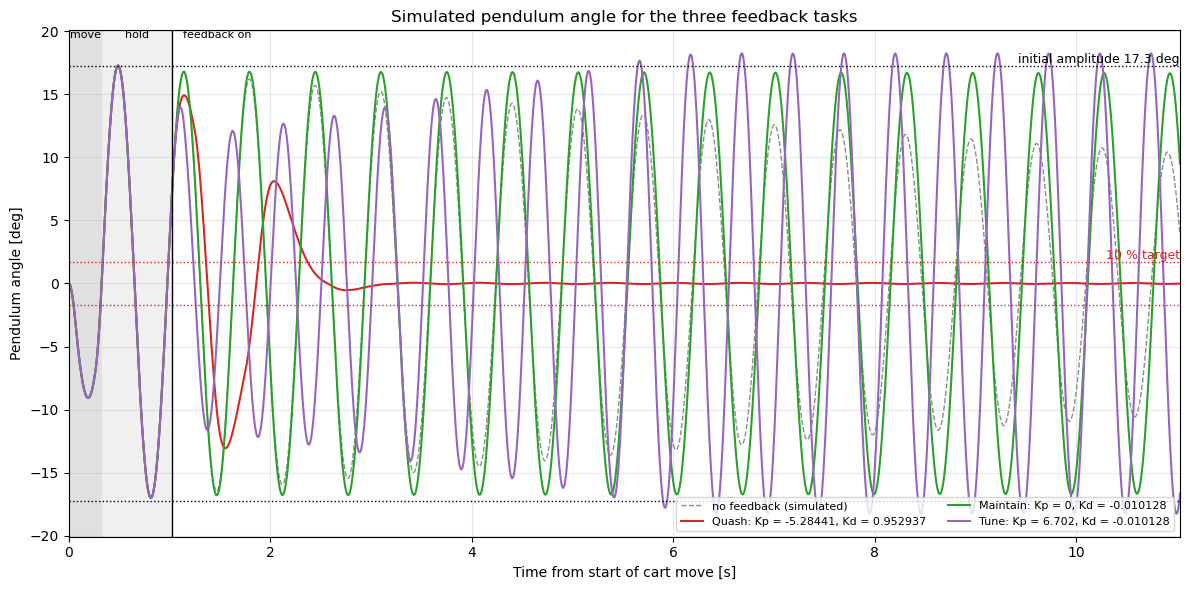

In [16]:
colors = {"Quash": "tab:red", "Maintain": "tab:green", "Tune": "tab:purple"}
fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(0, T_MOVE, color="0.88"); ax.axvspan(T_MOVE, T_CTRL, color="0.94")
ax.plot(sim_ctrl["t"], sim_ctrl["th"], color="0.55", lw=1, ls="--", label="no feedback (simulated)")
for name, g_ in GAINS.items():
    ax.plot(sim[name]["t"], sim[name]["th"], color=colors[name], lw=1.5,
            label=f"{name}: Kp = {g_['KP']:g}, Kd = {g_['KD']:g}")
for s_ in (+1, -1):
    ax.axhline(s_ * A0, color="k", ls=":", lw=1)
    ax.axhline(s_ * 0.1 * A0, color="tab:red", ls=":", lw=1)
ax.text(T_END, A0, f" initial amplitude {A0:.1f} deg", ha="right", va="bottom", fontsize=9)
ax.text(T_END, 0.1 * A0, " 10 % target", ha="right", va="bottom", fontsize=9, color="tab:red")
top = ax.get_ylim()[1]
ax.text(T_MOVE / 2, top, "move", ha="center", va="top", fontsize=8)
ax.text((T_MOVE + T_CTRL) / 2, top, "hold", ha="center", va="top", fontsize=8)
ax.text(T_CTRL + 0.1, top, "feedback on", ha="left", va="top", fontsize=8)
ax.axvline(T_CTRL, color="k", lw=1)
ax.set_xlim(0, T_END); ax.set_xlabel("Time from start of cart move [s]"); ax.set_ylabel("Pendulum angle [deg]")
ax.set_title("Simulated pendulum angle for the three feedback tasks")
ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig("fig_three_tasks_simulated.png", dpi=150); plt.show()

## 7. Report figures: one per task (hardware control, simulation, hardware with gains)

Curves that don't have hardware data yet are replaced by the simulated no-feedback curve, or left out.

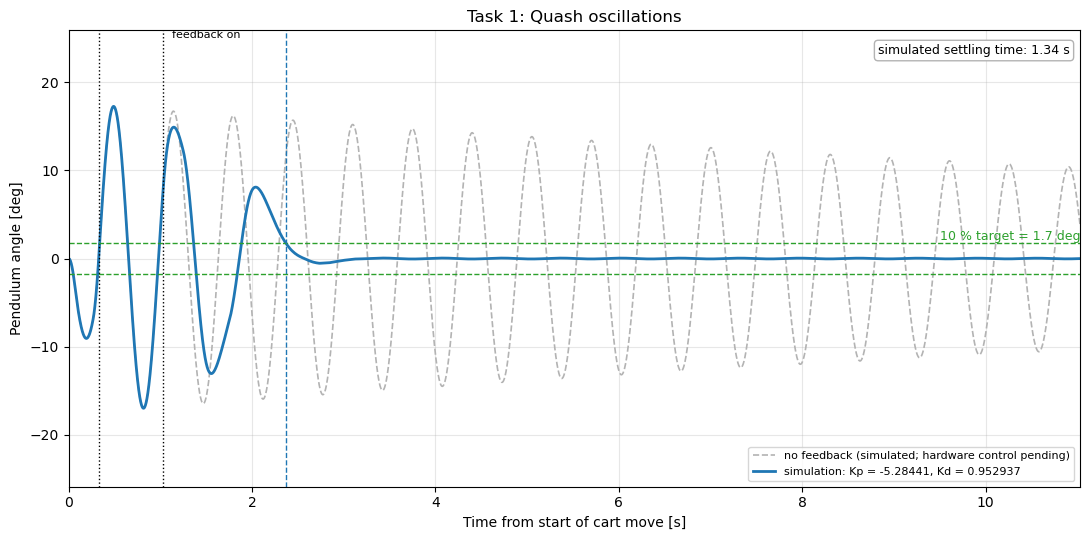

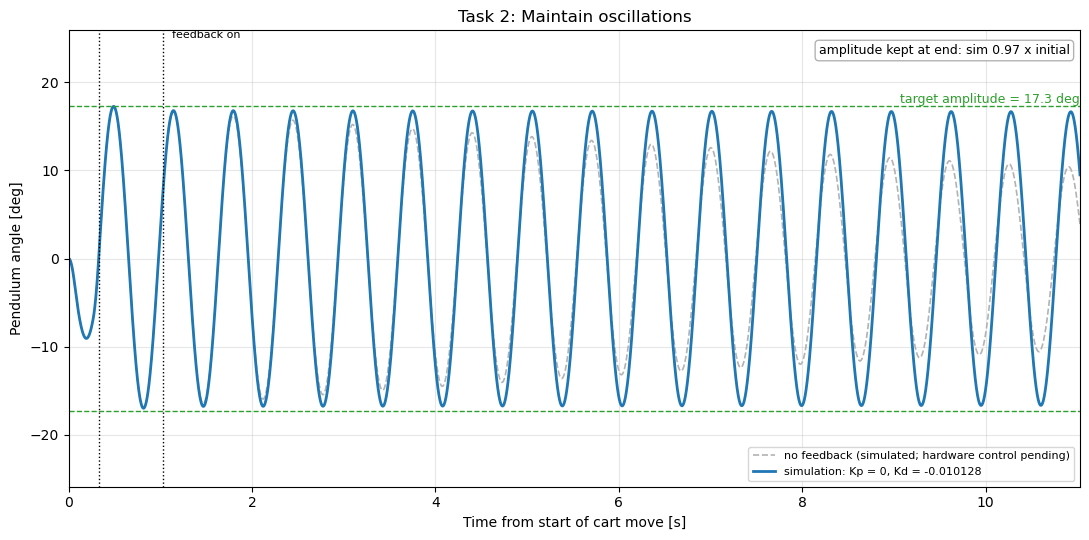

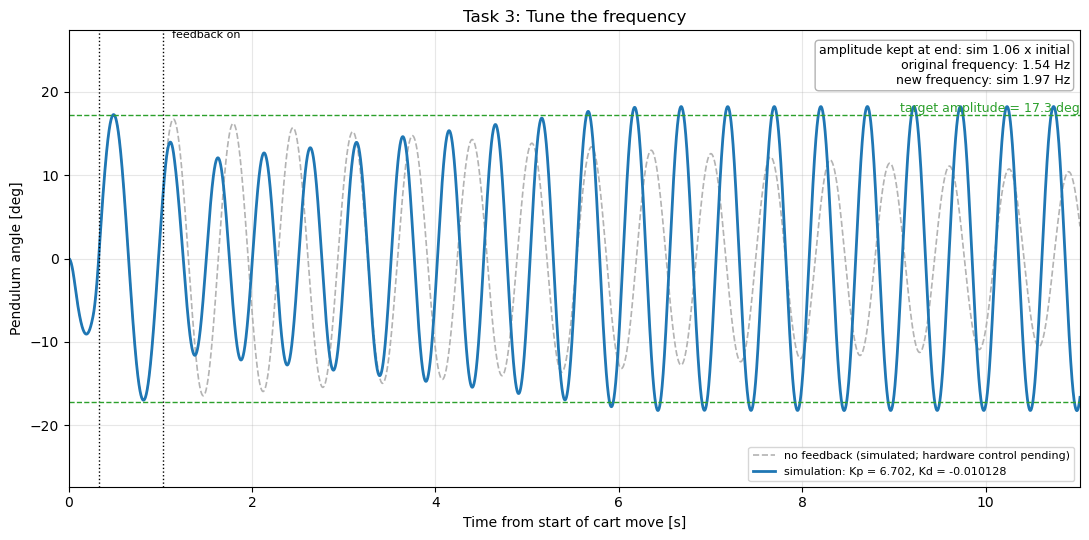

In [18]:
SPECS = [("Quash", "Task 1: Quash oscillations", "fig_task1_quash.png"),
         ("Maintain", "Task 2: Maintain oscillations", "fig_task2_maintain.png"),
         ("Tune", "Task 3: Tune the frequency", "fig_task3_tune.png")]
for name, title, fname in SPECS:
    g_, s, h = GAINS[name], sim[name], hw_res[name]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    if hw["Control"] is not None:
        ax.plot(*hw["Control"], color="0.55", lw=1.4, label="hardware, no feedback (control)")
    else:
        ax.plot(sim_ctrl["t"], sim_ctrl["th"], color="0.7", lw=1.2, ls="--", label="no feedback (simulated; hardware control pending)")
    ax.plot(s["t"], s["th"], color="tab:blue", lw=2, label=f"simulation: Kp = {g_['KP']:g}, Kd = {g_['KD']:g}")
    if hw[name] is not None:
        ax.plot(*hw[name], color="tab:red", lw=1.3, label=f"hardware: Kp = {g_['KP']:g}, Kd = {g_['KD']:g}")
    ax.axvline(T_MOVE, color="k", ls=":", lw=1); ax.axvline(T_CTRL, color="k", ls=":", lw=1)
    note = []
    if name == "Quash":
        for s_ in (+1, -1):
            ax.axhline(s_ * 0.1 * A0, color="tab:green", ls="--", lw=1)
        ax.text(T_END, 0.1 * A0, f" 10 % target = {0.1*A0:.1f} deg", color="tab:green", ha="right", va="bottom", fontsize=9)
        if not np.isnan(s["settle"]):
            ax.axvline(T_CTRL + s["settle"], color="tab:blue", ls="--", lw=1)
        note.append(f"simulated settling time: {fmt(s['settle'], '.2f')} s")
        if h: note.append(f"hardware settling time: {fmt(h['settle'], '.2f')} s")
    else:
        for s_ in (+1, -1):
            ax.axhline(s_ * A0, color="tab:green", ls="--", lw=1)
        ax.text(T_END, A0, f" target amplitude = {A0:.1f} deg", color="tab:green", ha="right", va="bottom", fontsize=9)
        note.append(f"amplitude kept at end: sim {fmt(s['end_ratio'], '.2f')} x initial" + (f", hw {fmt(h['end_ratio'], '.2f')}" if h else ""))
    if name == "Tune":
        f_orig = dominant_freq(*(lambda t_, th_: (t_[t_ >= T_CTRL], th_[t_ >= T_CTRL]))(*(hw["Control"] if hw["Control"] is not None else (sim_ctrl["t"], sim_ctrl["th"]))))
        note.append(f"original frequency: {f_orig:.2f} Hz")
        note.append(f"new frequency: sim {s['freq']:.2f} Hz" + (f", hw {h['freq']:.2f} Hz" if h else ""))
    ax.text(0.99, 0.97, "\n".join(note), transform=ax.transAxes, ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    lim = 1.5 * max(A0, np.abs(s["th"]).max())          # leave room for the annotation box and legend
    ax.set_ylim(-lim, lim)
    ax.text(T_CTRL + 0.1, lim, "feedback on", fontsize=8, va="top")
    ax.set_xlim(0, T_END); ax.set_xlabel("Time from start of cart move [s]"); ax.set_ylabel("Pendulum angle [deg]")
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=8)
    fig.tight_layout(); fig.savefig(fname, dpi=150); plt.show()

## 8. Optional: let the simulation suggest gains

Scans a small grid and reports what the *simulation* says works best. Use it as a check on the formula person's numbers, or as a starting point if theirs saturate the cart. Set `RUN_GAIN_SCAN = True` (takes about a minute).

In [20]:
RUN_GAIN_SCAN = False

if RUN_GAIN_SCAN:
    print("Task 1 (quash): settling time to <10 % [s]; blank = never settles")
    kps, kds = [-2, 0, 2, 4], [0.5, 1, 1.5, 2, 3, 4]
    tab = pd.DataFrame(index=[f"Kp={k}" for k in kps], columns=[f"Kd={k}" for k in kds])
    best = (np.inf, None)
    for kp in kps:
        for kd in kds:
            r = run_case(kp, kd)
            tab.loc[f"Kp={kp}", f"Kd={kd}"] = "" if np.isnan(r["settle"]) else f"{r['settle']:.2f}"
            if not np.isnan(r["settle"]) and r["settle"] < best[0]:
                best = (r["settle"], (kp, kd))
    print(tab.to_string()); print(f"best in grid: Kp, Kd = {best[1]} -> {best[0]:.2f} s\n")

    kd_m = GAINS["Maintain"]["KD"]
    print(f"Task 3 (tune): Kd = {kd_m:g} (from the Maintain gains), sweep Kp")
    out = []
    for kp in [2, 4, 6, 8, 10, 12, 14]:
        r = run_case(kp, kd_m)
        out.append({"Kp": kp, "freq [Hz]": round(r["freq"], 2), "amp kept": round(r["end_ratio"], 2),
                    "peak accel": round(r["peak_acc"], 2), "cart travel [mm]": round(r["travel_mm"])})
    print(pd.DataFrame(out).to_string(index=False))
    print("Look for the largest freq where 'amp kept' stays near 1 and peak accel stays below the cart limit.")